In [4]:
import sys
!{sys.executable} -m pip install --user tensorflow

In [11]:
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt

In [12]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [13]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Training images:", x_test.shape)
print("Training labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Training images: (10000, 28, 28)
Training labels: (10000,)


In [14]:
x_train = np.asarray(x_train, dtype=np.float32)
x_train /= 255.0
x_test = np.asarray(x_test, dtype=np.float32)
x_test /= 255.0

In [18]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

In [21]:
model.compile( optimizer=keras.optimizers.SGD(learning_rate=0.01),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'] )

In [22]:
history = model.fit( x_train, y_train ,
                   epochs = 10, batch_size=32, validation_split=0.1)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8299 - loss: 0.6880 - val_accuracy: 0.9165 - val_loss: 0.3269
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9018 - loss: 0.3539 - val_accuracy: 0.9273 - val_loss: 0.2632
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9135 - loss: 0.3047 - val_accuracy: 0.9330 - val_loss: 0.2359
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9225 - loss: 0.2747 - val_accuracy: 0.9393 - val_loss: 0.2163
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9288 - loss: 0.2517 - val_accuracy: 0.9448 - val_loss: 0.1992
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9340 - loss: 0.2331 - val_accuracy: 0.9503 - val_loss: 0.1847
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9390 - loss: 0.2172 - val_accuracy: 0.9513 - val_loss: 0.1748
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9428 - loss: 0.2028 

In [23]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9514 - loss: 0.1705
Test Loss: 0.17051704227924347
Test Accuracy: 95.13999819755554 %


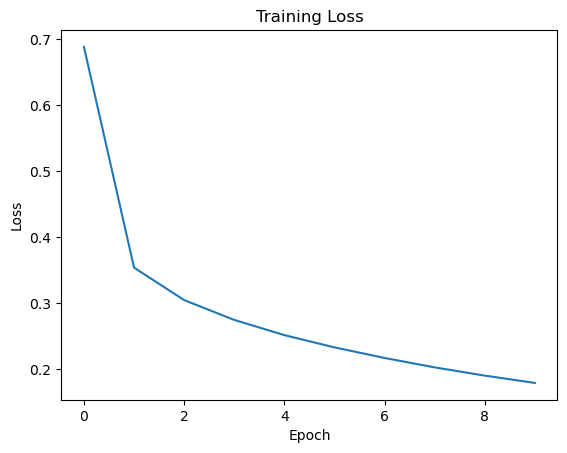

In [25]:
plt.plot(history.history[ 'loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()